# Día 4 — Random Forest para series de tiempo

**Módulo 5: Econometría y Forecasting con IA — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 09-11-2026 · **Unidad 3. Forecasting con IA** · Contenidos 3.2, 3.3 y 3.4

El Día 3 terminó con un descubrimiento: **una serie de tiempo se puede convertir en una tabla**. Cada fila es un mes, el objetivo es la inflación de ese mes y los predictores son valores anteriores. Con esa tabla, una regresión lineal sobre el rezago 1 dio exactamente el AR(1).

Hoy cambiamos la regresión lineal por el modelo que mejor funcionó en el Módulo 3: **Random Forest**. Y respondemos tres preguntas:

1. ¿Qué variables conviene darle al modelo? (3.2)
2. ¿Cómo se valida un modelo de Machine Learning sin mezclar el tiempo? (3.3)
3. ¿Cómo se pronostica **varios meses** con un modelo que aprendió a pronosticar **uno**? (3.4)

## Objetivos de la jornada

Al terminar deberías poder explicar, con tus propias palabras:

- cómo construir una **tabla de variables temporales** (rezagos, promedios móviles, mes del año) sin fuga de información;
- por qué `train_test_split` con mezcla aleatoria **no sirve** para series, y cómo funciona **`TimeSeriesSplit`**;
- cómo ajustar los **hiperparámetros** de Random Forest con validación temporal;
- qué variables usó más el modelo (**importancia de variables**);
- la diferencia entre el pronóstico **recursivo** y el **directo**, y cuándo conviene cada uno;
- por qué Random Forest no siempre supera a un promedio móvil.

## Ruta del día

| Parte | Qué haremos | Herramienta |
|---|---|---|
| 1 | Recordar Random Forest del Módulo 3 | — |
| 2 | Construir la tabla de variables temporales | `shift`, `rolling` |
| 3 | Separar Train y Test por fecha | — |
| 4 | Línea base sobre la misma tabla | — |
| 5 | Primer Random Forest: sobreajuste | `RandomForestRegressor` |
| 6 | Validación temporal con `TimeSeriesSplit` | `TimeSeriesSplit`, `cross_val_score` |
| 7 | Hiperparámetros uno por uno y `GridSearchCV` | `GridSearchCV` |
| 8 | Importancia de variables | `feature_importances_` |
| 9 | Test una sola vez | — |
| 10 | Pronóstico recursivo frente a directo | funciones propias |
| 11 | Pronóstico de los próximos tres meses y reto | — |

## Preparación: ejecuta estas dos celdas primero

Funcionan igual en tu computador (Anaconda + Jupyter) y en Google Colab:

1. **Instalación de librerías.** `%pip install` instala lo que falte; si ya está instalado, no hace nada.
2. **Datos.** Si encuentra la carpeta `datos/` del repositorio, la usa. Si no la encuentra (por ejemplo en Colab), descarga los archivos desde GitHub.

Si Colab pide *"Restart session"* después de instalar, acéptalo y vuelve a ejecutar desde aquí.

In [1]:
# 1) Librerías de este notebook (en local no reinstala lo que ya tienes; en Colab instala lo que falte)
%pip install -q numpy pandas matplotlib statsmodels scikit-learn

Note: you may need to restart the kernel to use updated packages.


# 0. Librerías

Hoy todo viene de **scikit-learn**, la librería del Módulo 3. Lo nuevo es `TimeSeriesSplit`, la versión temporal del K-Fold. Usamos statsmodels solo para traer el SARIMA del Día 3 a la comparación final.

| Herramienta | Para qué |
|---|---|
| `RandomForestRegressor` | el modelo |
| `TimeSeriesSplit` | pliegues de validación que respetan el orden del tiempo |
| `cross_val_score` | evaluar una configuración en todos los pliegues |
| `GridSearchCV` | probar combinaciones de hiperparámetros |
| `ARIMA` (statsmodels) | el SARIMA del Día 3, para comparar |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# scikit-learn
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, KFold, cross_val_score, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error

# statsmodels (solo para la comparación final)
from statsmodels.tsa.arima.model import ARIMA

import warnings
warnings.filterwarnings('ignore')

In [3]:
# 2) Datos: usa la carpeta 'datos' del repositorio si existe; si no (Colab), descarga los archivos de GitHub
from pathlib import Path
import urllib.request

URL_DATOS = 'https://raw.githubusercontent.com/jonarosero/modulo5_econometria_forecasting_ia/main/datos'
ARCHIVOS = [          # archivos que usa ESTE notebook
    'series_economicas.csv',
]

# Buscamos el ARCHIVO (no solo la carpeta): Jupyter abierto en la raíz -> 'datos'; en notebooks/ -> '../datos'
DATA_DIR = next((c for c in [Path('datos'), Path('../datos')] if (c / ARCHIVOS[0]).exists()), None)

if DATA_DIR is None:                       # no está en este computador: lo descargamos (caso Colab)
    DATA_DIR = Path('datos')
    for archivo in ARCHIVOS:
        destino = DATA_DIR / archivo
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_DATOS}/{archivo}', destino)
        print('Descargado:', archivo)

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: /tmp/m5repo/datos


In [4]:
series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')
y = series['ipc_var_mensual'].loc['2005':].dropna()

print(f'{len(y)} meses, de {y.index.min():%b %Y} a {y.index.max():%b %Y}')

260 meses, de Jan 2005 a Aug 2026


**Qué obtuvimos:** la misma inflación mensual de los días anteriores (260 meses). El objetivo sigue siendo pronosticarla.

# 1. Repaso: ¿qué hace un Random Forest?

En el Módulo 3 (Días 2 y 3) vimos que:

- un **árbol de decisión** hace preguntas del tipo "¿el rezago 1 es mayor que 0.35?" y, en cada hoja, predice el **promedio** de los casos de entrenamiento que llegaron ahí;
- un **Random Forest** entrena **muchos árboles**, cada uno con una muestra distinta de filas y de columnas, y **promedia** sus predicciones;
- promediar árboles distintos reduce el sobreajuste de un árbol individual.

### ¿Qué aporta frente a un AR o un ARIMA?

| | AR / ARIMA | Random Forest |
|---|---|---|
| Relación entre pasado y presente | **lineal**: $y_t = c + \phi\,y_{t-1}$ | **no lineal**: puede aprender "si el mes pasado fue muy alto **y** es abril, entonces…" |
| Variables | rezagos de la serie (y `exog`) | cualquier columna: rezagos, promedios, mes, otras series |
| Interpretación | coeficientes con significado económico | importancia de variables |
| Intervalos de predicción | sí, con fundamento estadístico | no directamente |
| Extrapolación | puede pronosticar valores nunca vistos | **no**: solo predice promedios de lo que ya vio |

La última fila es importante: un árbol nunca predice un valor mayor que el máximo de su entrenamiento. Para una serie estacionaria como la inflación no es un problema grave; para una serie con tendencia (el IPC en nivel) sí lo sería, y por eso se trabaja con la serie diferenciada.

# 2. La tabla de variables temporales (3.2)

## 2.1 Qué variables crear y por qué

Cada columna debe responder a algo que aprendimos de la serie en los días anteriores:

| Variable | Cálculo | ¿Por qué? (evidencia) |
|---|---|---|
| `rezago_1` | $y_{t-1}$ | ACF y PACF: el rezago más fuerte (Días 1 y 2) |
| `rezago_2`, `rezago_3` | $y_{t-2}$, $y_{t-3}$ | la ACF sigue fuera de la banda en 2 y 3 |
| `rezago_6` | $y_{t-6}$ | bastón en la PACF (Día 2) |
| `rezago_12` | $y_{t-12}$ | **estacionalidad** (ACF y PACF en el rezago 12) |
| `media_3` | promedio de $y_{t-1}, y_{t-2}, y_{t-3}$ | nivel reciente, menos ruidoso que un solo mes |
| `media_12` | promedio de los 12 meses anteriores | la mejor línea base de los Días 2 y 3 |
| `mes` | número del mes (1 a 12) | patrón estacional (Día 1: enero, abril y septiembre) |

### La regla de oro: todo predictor debe conocerse **antes** del mes que se pronostica

- `rezago_1` de marzo es febrero → conocido a fines de febrero. ✔
- `media_3` de marzo debe promediar **diciembre, enero y febrero**, no enero, febrero y marzo. Por eso se calcula como `y.shift(1).rolling(3).mean()`: primero se desplaza y luego se promedia.
- `mes` se conoce siempre: el calendario no es información futura. ✔

## 2.2 Una fila a mano

Construyamos la fila de **marzo de 2025** con los valores reales:

| Variable | Mes que usa | Valor |
|---|---|---:|
| `rezago_1` | feb 2025 | 0.09 |
| `rezago_2` | ene 2025 | −0.15 |
| `rezago_3` | dic 2024 | −0.99 |
| `rezago_6` | sep 2024 | 0.18 |
| `rezago_12` | mar 2024 | 0.29 |
| `media_3` | (0.09 − 0.15 − 0.99) / 3 | −0.35 |
| `mes` | marzo | 3 |
| **objetivo** | **mar 2025** | **0.35** |

**Qué vamos a hacer:** escribir una función que construya la tabla completa y verificar que la fila de marzo de 2025 coincide.

In [5]:
REZAGOS = [1, 2, 3, 6, 12]

def tabla_variables(serie):
    """Tabla de aprendizaje supervisado: cada fila es un mes; los predictores solo usan meses anteriores."""
    tabla = pd.DataFrame({'objetivo': serie})

    # Rezagos: el valor de k meses antes.
    for k in REZAGOS:
        tabla[f'rezago_{k}'] = serie.shift(k)

    # Promedios móviles del pasado: primero shift(1), luego rolling.
    tabla['media_3'] = serie.shift(1).rolling(3).mean()
    tabla['media_12'] = serie.shift(1).rolling(12).mean()

    # Calendario.
    tabla['mes'] = serie.index.month

    # Las primeras filas no tienen todos los rezagos: se eliminan.
    return tabla.dropna()

tabla = tabla_variables(y)

print('Filas:', len(tabla), '· desde', tabla.index.min().strftime('%b %Y'))
print('Columnas:', tabla.columns.tolist())
tabla.loc[['2025-03-01']].round(2)

Filas: 248 · desde Jan 2006
Columnas: ['objetivo', 'rezago_1', 'rezago_2', 'rezago_3', 'rezago_6', 'rezago_12', 'media_3', 'media_12', 'mes']


,objetivo,rezago_1,rezago_2,rezago_3,rezago_6,rezago_12,media_3,media_12,mes
fecha,,,,,,,,,
2025-03-01,0.35,0.09,-0.15,-0.99,0.18,0.29,-0.35,0.02,3


**Qué obtuvimos:** 248 filas (se pierden los 12 primeros meses de 2005 porque `rezago_12` y `media_12` no tienen suficiente historia) y la fila de marzo de 2025 coincide con la tabla a mano.

### Comprobar que no hay fuga de información

Una prueba sencilla: si por error algún predictor contuviera el valor del propio mes, su correlación con el objetivo sería 1. Revisemos las correlaciones.

In [6]:
tabla.corr()['objetivo'].drop('objetivo').sort_values(ascending=False).round(3)

rezago_1     0.371
media_3      0.355
media_12     0.343
rezago_12    0.288
rezago_2     0.226
rezago_3     0.192
rezago_6     0.184
mes         -0.268
Name: objetivo, dtype: float64

Ninguna correlación se acerca a 1; la mayor es la de `rezago_1` (≈ 0.37), igual a la autocorrelación del Día 1. **No hay fuga.** Si alguna vez una variable de un modelo de series tiene correlación ≈ 1 con el objetivo, sospecha primero de un `shift` olvidado.

Separamos predictores ($X$) y objetivo ($y$), como en el Módulo 3.

In [7]:
X = tabla.drop(columns='objetivo')
objetivo = tabla['objetivo']

print('X:', X.shape, '· objetivo:', objetivo.shape)

X: (248, 8) · objetivo: (248,)


# 3. Train y Test por fecha

## 3.1 ¿Por qué no `train_test_split`?

En el Módulo 3 usábamos `train_test_split(X, y, test_size=0.2, random_state=42)`, que **mezcla** las filas al azar. En una serie, eso significa que el modelo podría entrenar con junio de 2025 y probarse en mayo de 2025: estaría usando el futuro.

Además, como `rezago_1` de un mes es el objetivo del mes anterior, una mezcla aleatoria pone en Train filas que contienen, casi literalmente, las respuestas del Test. El error medido sería **demasiado optimista**.

**Separamos por fecha**, igual que en los días anteriores.

In [8]:
X_train, y_train = X.loc[:'2024-12'], objetivo.loc[:'2024-12']
X_test, y_test = X.loc['2025-01':], objetivo.loc['2025-01':]

print(f'Train: {len(X_train)} meses ({X_train.index.min():%b %Y} – {X_train.index.max():%b %Y})')
print(f'Test:  {len(X_test)} meses ({X_test.index.min():%b %Y} – {X_test.index.max():%b %Y})')

Train: 228 meses (Jan 2006 – Dec 2024)
Test:  20 meses (Jan 2025 – Aug 2026)


**Qué obtuvimos:** 228 meses para entrenar y validar (2006–2024) y 20 para el Test (2025 – agosto 2026). Dentro de Train haremos la validación con `TimeSeriesSplit` (parte 6). El Test no se toca hasta la parte 9.

# 4. Línea base sobre la misma tabla

Antes de entrenar, definimos qué hay que superar. Dos pronósticos simples ya están **dentro de la tabla**:

- el **ingenuo** es la columna `rezago_1`;
- el **promedio móvil de 12** es la columna `media_12`, la mejor línea base de los Días 2 y 3.

In [9]:
def metricas(real, pred):
    return {
        'MAE': mean_absolute_error(real, pred),
        'RMSE': np.sqrt(mean_squared_error(real, pred)),
        'Bias': np.mean(np.asarray(pred) - np.asarray(real)),
    }

pd.DataFrame({
    'Ingenuo (rezago_1)': metricas(y_test, X_test['rezago_1']),
    'Promedio móvil 12 (media_12)': metricas(y_test, X_test['media_12']),
}).T.round(3)

,MAE,RMSE,Bias
Ingenuo (rezago_1),0.478,0.618,-0.051
Promedio móvil 12 (media_12),0.286,0.405,-0.066


**Para recordar:** en el Test, el promedio móvil de 12 tiene MAE ≈ 0.29. Es la cifra que Random Forest debería mejorar. (Solo la miramos para fijar la meta; no la usaremos para tomar decisiones.)

# 5. Primer Random Forest: el sobreajuste reaparece

**Qué vamos a hacer:** entrenar un Random Forest con los hiperparámetros por defecto y medir su error **en el propio Train**.

`RandomForestRegressor` tiene los mismos parámetros del Módulo 3. Fijamos `random_state=42` para que los resultados sean reproducibles y `n_jobs=-1` para usar todos los núcleos del procesador.

In [10]:
rf_defecto = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_defecto.fit(X_train, y_train)

print('MAE en Train:', round(mean_absolute_error(y_train, rf_defecto.predict(X_train)), 3))

MAE en Train: 0.091


**Qué obtuvimos:** un MAE en Train de ≈ 0.09, **muy por debajo** de cualquier método que hemos visto (≈ 0.22–0.25). ¿Es un gran modelo?

No lo sabemos todavía: con los valores por defecto, cada árbol crece hasta que cada hoja tiene un solo mes, así que **memoriza** el Train. Es el sobreajuste del Módulo 3. Para saber cuánto vale de verdad, necesitamos medirlo en meses que **no** usó para entrenar, sin tocar el Test. Eso es la validación temporal.

# 6. Validación temporal con `TimeSeriesSplit` (3.3)

## 6.1 La idea

`TimeSeriesSplit` es el **origen móvil** del Día 2 aplicado a una tabla: divide las filas en bloques consecutivos y, en cada pliegue, entrena con todo lo anterior y valida con el bloque siguiente.

Con `n_splits=5` y 228 filas:

| Pliegue | Entrena con | Valida con |
|---:|---|---|
| 1 | bloque 1 | bloque 2 |
| 2 | bloques 1–2 | bloque 3 |
| 3 | bloques 1–3 | bloque 4 |
| 4 | bloques 1–4 | bloque 5 |
| 5 | bloques 1–5 | bloque 6 |

**Diferencia con el K-Fold del Módulo 3:** en K-Fold, cada pliegue usa como entrenamiento bloques **anteriores y posteriores** al de validación. En `TimeSeriesSplit`, el entrenamiento está **siempre antes**.

**Qué vamos a hacer:** crear el divisor y mostrar las fechas de cada pliegue.

In [11]:
tscv = TimeSeriesSplit(n_splits=5)

for i, (filas_train, filas_val) in enumerate(tscv.split(X_train), start=1):
    print(f'Pliegue {i}: entrena {len(filas_train):3d} meses '
          f'({X_train.index[filas_train[0]]:%b %Y} – {X_train.index[filas_train[-1]]:%b %Y}) · '
          f'valida {len(filas_val)} meses ({X_train.index[filas_val[0]]:%b %Y} – {X_train.index[filas_val[-1]]:%b %Y})')

Pliegue 1: entrena  38 meses (Jan 2006 – Feb 2009) · valida 38 meses (Mar 2009 – Apr 2012)
Pliegue 2: entrena  76 meses (Jan 2006 – Apr 2012) · valida 38 meses (May 2012 – Jun 2015)
Pliegue 3: entrena 114 meses (Jan 2006 – Jun 2015) · valida 38 meses (Jul 2015 – Aug 2018)
Pliegue 4: entrena 152 meses (Jan 2006 – Aug 2018) · valida 38 meses (Sep 2018 – Oct 2021)
Pliegue 5: entrena 190 meses (Jan 2006 – Oct 2021) · valida 38 meses (Nov 2021 – Dec 2024)


**Qué obtuvimos:** 5 pliegues. El entrenamiento crece de 38 a 190 meses y cada validación tiene 38 meses (algo más de 3 años). El último pliegue valida de noviembre de 2021 a diciembre de 2024. En total se validan 190 meses distintos.

## 6.2 Comparar `TimeSeriesSplit` con un K-Fold mezclado

**Qué vamos a hacer:** evaluar el mismo Random Forest con los dos esquemas, para ver cuánto engaña la mezcla aleatoria.

`cross_val_score` entrena y evalúa en cada pliegue y devuelve una puntuación por pliegue. Con `scoring='neg_mean_absolute_error'` devuelve el MAE **con signo negativo** (scikit-learn siempre maximiza; Módulo 3, Día 0.1), así que le cambiamos el signo.

In [12]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

mae_temporal = -cross_val_score(rf, X_train, y_train, cv=tscv, scoring='neg_mean_absolute_error')
mae_mezclado = -cross_val_score(rf, X_train, y_train, cv=KFold(n_splits=5, shuffle=True, random_state=42),
                                scoring='neg_mean_absolute_error')

pd.DataFrame({
    'TimeSeriesSplit': mae_temporal,
    'KFold mezclado (INCORRECTO)': mae_mezclado,
}, index=[f'pliegue {i}' for i in range(1, 6)]).round(3)

,TimeSeriesSplit,KFold mezclado (INCORRECTO)
pliegue 1,0.215,0.224
pliegue 2,0.231,0.242
pliegue 3,0.217,0.276
pliegue 4,0.251,0.229
pliegue 5,0.298,0.259


In [13]:
print('MAE medio con TimeSeriesSplit:', round(mae_temporal.mean(), 3))
print('MAE medio con KFold mezclado: ', round(mae_mezclado.mean(), 3))

MAE medio con TimeSeriesSplit: 0.242
MAE medio con KFold mezclado:  0.246


**Lectura:** en la inflación los dos promedios son casi iguales (≈ 0.242 y ≈ 0.246). ¿Entonces da igual? **No.** La inflación tiene poca memoria (su autocorrelación de rezago 1 es solo 0.37), así que "ver el futuro" le sirve poco al modelo. En una serie **persistente** la trampa es enorme. Comprobémoslo con el **riesgo país**, cuyo nivel cambia poco de un mes a otro.

**Qué vamos a hacer:** construir una tabla de rezagos del riesgo país (2005–2024) y evaluar el mismo Random Forest con los dos esquemas.

In [14]:
riesgo = series['riesgo_pais_pb'].loc['2005':'2024'].dropna()

tabla_riesgo = pd.DataFrame({'objetivo': riesgo})
for k in [1, 2, 3, 12]:
    tabla_riesgo[f'rezago_{k}'] = riesgo.shift(k)
tabla_riesgo = tabla_riesgo.dropna()

X_r, y_r = tabla_riesgo.drop(columns='objetivo'), tabla_riesgo['objetivo']

mae_r_temporal = -cross_val_score(rf, X_r, y_r, cv=TimeSeriesSplit(n_splits=5), scoring='neg_mean_absolute_error').mean()
mae_r_mezclado = -cross_val_score(rf, X_r, y_r, cv=KFold(n_splits=5, shuffle=True, random_state=42),
                                  scoring='neg_mean_absolute_error').mean()

print(f'Riesgo país · MAE con TimeSeriesSplit: {mae_r_temporal:.0f} puntos básicos')
print(f'Riesgo país · MAE con KFold mezclado:  {mae_r_mezclado:.0f} puntos básicos')

Riesgo país · MAE con TimeSeriesSplit: 262 puntos básicos
Riesgo país · MAE con KFold mezclado:  147 puntos básicos


**Lectura:** con el K-Fold mezclado, el error del riesgo país parece **≈ 44 % menor** (≈ 147 frente a ≈ 262 puntos básicos). Es una ilusión: al mezclar, el modelo entrena con meses vecinos posteriores al que valida, y como la serie cambia poco, "copia" la respuesta. **El número honesto es siempre el de `TimeSeriesSplit`.**

Volviendo a la inflación: el error cambia bastante entre pliegues temporales. El último (noviembre 2021 – diciembre 2024, con los choques de 2024) es el más difícil (≈ 0.30). Es la misma lección del Día 2: un solo periodo de validación no basta.

## 6.3 La línea base en los mismos pliegues

Para comparar con justicia, calculamos el MAE del promedio móvil de 12 en los **mismos** bloques de validación.

In [15]:
mae_base_pliegues = [
    mean_absolute_error(y_train.iloc[filas_val], X_train['media_12'].iloc[filas_val])
    for _, filas_val in tscv.split(X_train)
]

print('MAE promedio móvil 12 (mismos pliegues):', round(np.mean(mae_base_pliegues), 3))
print('MAE Random Forest por defecto:          ', round(mae_temporal.mean(), 3))

MAE promedio móvil 12 (mismos pliegues): 0.249
MAE Random Forest por defecto:           0.242


**Qué obtuvimos:** con los valores por defecto, Random Forest (≈ 0.24) ya mejora un poco al promedio móvil (≈ 0.25) en validación temporal. Veamos si ajustar sus hiperparámetros ayuda.

# 7. Hiperparámetros, uno por uno

Como en el Módulo 3, primero entendemos cada hiperparámetro por separado y después probamos combinaciones.

| Hiperparámetro | Qué controla | Valores pequeños | Valores grandes |
|---|---|---|---|
| `max_depth` | cuántas preguntas seguidas puede hacer un árbol | árboles simples (subajuste) | árboles que memorizan (sobreajuste) |
| `min_samples_leaf` | cuántos meses mínimo debe tener cada hoja | hojas de 1 mes: memoriza | hojas grandes: predicciones suaves |
| `max_features` | qué fracción de columnas considera en cada división | árboles más distintos entre sí | árboles parecidos |
| `n_estimators` | cuántos árboles se promedian | promedio inestable | más estable, pero más lento |

## 7.1 `max_depth`

**Qué vamos a hacer:** probar varias profundidades y medir el MAE en Train y en validación temporal.

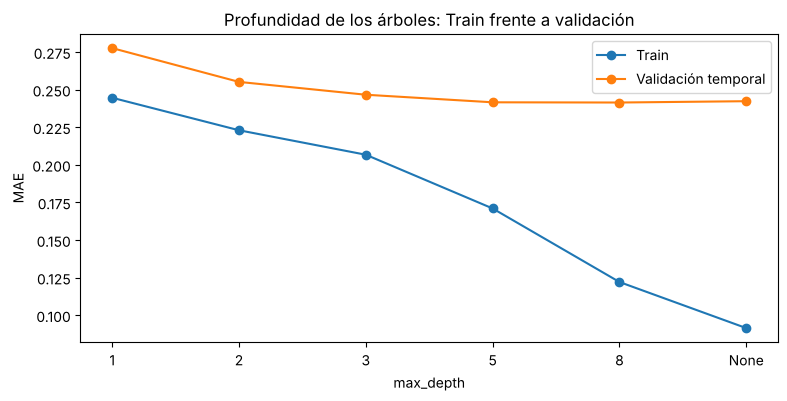

,MAE_Train,MAE_Validacion
max_depth,,
1,0.245,0.278
2,0.223,0.255
3,0.207,0.247
5,0.171,0.242
8,0.122,0.241
None,0.091,0.242


In [16]:
def evaluar_rf(**parametros):
    modelo = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, **parametros)
    mae_val = -cross_val_score(modelo, X_train, y_train, cv=tscv, scoring='neg_mean_absolute_error').mean()
    modelo.fit(X_train, y_train)
    mae_tr = mean_absolute_error(y_train, modelo.predict(X_train))
    return mae_tr, mae_val

filas = []
for profundidad in [1, 2, 3, 5, 8, None]:
    mae_tr, mae_val = evaluar_rf(max_depth=profundidad)
    filas.append({'max_depth': str(profundidad), 'MAE_Train': mae_tr, 'MAE_Validacion': mae_val})

prof = pd.DataFrame(filas).set_index('max_depth')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(prof.index, prof['MAE_Train'], marker='o', label='Train')
ax.plot(prof.index, prof['MAE_Validacion'], marker='o', label='Validación temporal')
ax.set_xlabel('max_depth')
ax.set_ylabel('MAE')
ax.set_title('Profundidad de los árboles: Train frente a validación')
ax.legend()
plt.show()

prof.round(3)

### Lectura: la curva clásica del Módulo 3

- **Train** baja sin parar al aumentar la profundidad: con árboles sin límite, ≈ 0.09.
- **Validación** baja hasta una profundidad de 3–5 (≈ 0.24) y luego se estanca.
- La distancia entre ambas curvas crece: es el **sobreajuste**. Más profundidad no mejora la validación; solo memoriza.

## 7.2 `min_samples_leaf`

In [17]:
filas = []
for hoja in [1, 5, 10, 20, 40]:
    mae_tr, mae_val = evaluar_rf(min_samples_leaf=hoja)
    filas.append({'min_samples_leaf': hoja, 'MAE_Train': mae_tr, 'MAE_Validacion': mae_val})

pd.DataFrame(filas).set_index('min_samples_leaf').round(3)

,MAE_Train,MAE_Validacion
min_samples_leaf,,
1,0.091,0.242
5,0.160,0.254
10,0.199,0.255
20,0.221,0.268
40,0.239,0.287


**Lectura:** al exigir hojas más grandes, el Train empeora (el modelo ya no puede memorizar) y la validación **también** empeora poco a poco. Con esta serie, hojas pequeñas combinadas con una profundidad limitada funcionan mejor. Con hojas de 40 meses, el modelo se vuelve casi una media histórica.

## 7.3 `n_estimators`

In [18]:
for arboles in [10, 50, 100, 300]:
    modelo = RandomForestRegressor(n_estimators=arboles, max_depth=5, random_state=42, n_jobs=-1)
    mae_val = -cross_val_score(modelo, X_train, y_train, cv=tscv, scoring='neg_mean_absolute_error').mean()
    print(f'{arboles:4d} árboles · MAE validación = {mae_val:.3f}')

  10 árboles · MAE validación = 0.246


  50 árboles · MAE validación = 0.244


 100 árboles · MAE validación = 0.242


 300 árboles · MAE validación = 0.243


**Lectura:** de 10 a 100 árboles el error baja un poco y luego se estabiliza. Más árboles **no** causan sobreajuste; solo cuestan tiempo. 100 es suficiente aquí.

## 7.4 Probar combinaciones con `GridSearchCV`

`GridSearchCV` (Módulo 3, Día 6) prueba todas las combinaciones de una grilla y elige la de menor error en validación. La única diferencia hoy es **`cv=tscv`**: los pliegues respetan el tiempo.

| Parámetro de `GridSearchCV` | Valor |
|---|---|
| `estimator` | el Random Forest base |
| `param_grid` | diccionario con los valores a probar |
| `cv` | **`tscv`** (nunca un K-Fold mezclado) |
| `scoring` | `'neg_mean_absolute_error'` |

La grilla tiene 3 × 3 × 2 = 18 combinaciones; con 5 pliegues son 90 entrenamientos (unos 15 segundos).

In [19]:
grilla = {
    'max_depth': [3, 5, None],
    'min_samples_leaf': [1, 5, 20],
    'max_features': [1.0, 0.5],
}

busqueda = GridSearchCV(
    estimator=RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    param_grid=grilla,
    cv=tscv,
    scoring='neg_mean_absolute_error',
)
busqueda.fit(X_train, y_train)

print('Mejor combinación:', busqueda.best_params_)
print('MAE de validación:', round(-busqueda.best_score_, 3))

Mejor combinación: {'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 1}
MAE de validación: 0.239


In [20]:
# Las cinco mejores combinaciones.
resultados_grilla = pd.DataFrame(busqueda.cv_results_)
resultados_grilla['MAE_validacion'] = -resultados_grilla['mean_test_score']
resultados_grilla['desv_entre_pliegues'] = resultados_grilla['std_test_score']
resultados_grilla.sort_values('MAE_validacion')[['params', 'MAE_validacion', 'desv_entre_pliegues']].head(5).round(3)

,params,MAE_validacion,desv_entre_pliegues
9,"{'max_depth': 5, 'max_features': 0.5, 'min_sam...",0.239,0.035
15,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.240,0.033
3,"{'max_depth': 3, 'max_features': 0.5, 'min_sam...",0.241,0.030
6,"{'max_depth': 5, 'max_features': 1.0, 'min_sam...",0.242,0.030
12,"{'max_depth': None, 'max_features': 1.0, 'min_...",0.242,0.031


### Lectura

- La mejor combinación usa árboles de **profundidad 5**, **hojas de 1 mes** y la **mitad de las columnas** en cada división (`max_features=0.5`), con MAE de validación ≈ 0.239.
- Las cinco mejores están a menos de 0.01 entre sí, y la desviación entre pliegues es mayor que esa diferencia. **La elección no es crítica**: cualquiera de ellas es razonable.
- Frente a la línea base en los mismos pliegues (≈ 0.249), el Random Forest ajustado mejora ≈ 0.01: una mejora **pequeña**.

In [21]:
rf_final = busqueda.best_estimator_   # ya reentrenado con todo el Train

print('MAE en Train:', round(mean_absolute_error(y_train, rf_final.predict(X_train)), 3))

MAE en Train: 0.174


El modelo elegido tiene un MAE en Train de ≈ 0.17: sigue ajustando mejor el Train que la validación (≈ 0.24), pero la brecha es mucho menor que con los valores por defecto (0.09 frente a 0.24).

# 8. Importancia de variables

`feature_importances_` indica cuánto redujo el error, en promedio, cada variable al ser usada en las divisiones de los árboles. Suman 1.

**Recordatorio del Módulo 3:** una importancia es **predictiva**, no causal. Dice "el modelo usó mucho esta columna", no "esta variable causa la inflación".

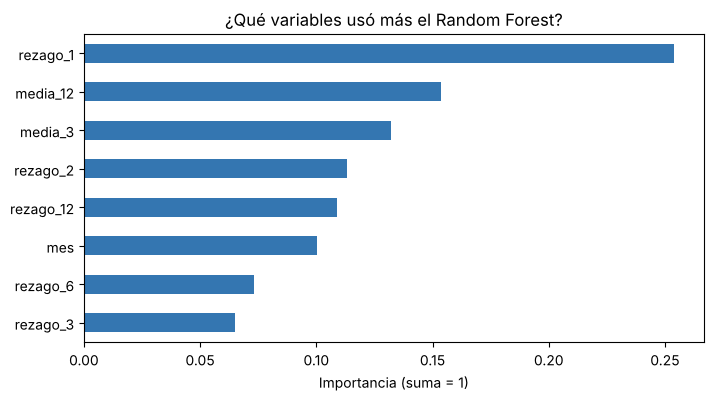

rezago_1     0.254
media_12     0.153
media_3      0.132
rezago_2     0.113
rezago_12    0.109
mes          0.100
rezago_6     0.073
rezago_3     0.065
dtype: float64

In [22]:
importancia = pd.Series(rf_final.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
importancia.plot.barh(ax=ax, color='#3476B1')
ax.set_xlabel('Importancia (suma = 1)')
ax.set_title('¿Qué variables usó más el Random Forest?')
plt.show()

importancia.sort_values(ascending=False).round(3)

### Lectura

| Variable | Importancia | Coherencia con lo que sabíamos |
|---|---:|---|
| `rezago_1` | ≈ 0.25 | el rezago más fuerte en la ACF y la PACF |
| `media_12` | ≈ 0.15 | la mejor línea base: el nivel de fondo |
| `media_3` | ≈ 0.13 | el nivel reciente |
| `rezago_2`, `rezago_12`, `mes` | ≈ 0.10–0.11 cada una | dependencia corta y estacionalidad |
| `rezago_6`, `rezago_3` | ≈ 0.07 | aportan poco |

El Random Forest "redescubrió" lo que vimos con la ACF: el mes anterior, el nivel de fondo y el patrón anual. Ninguna variable domina: el modelo combina varias señales débiles.

# 9. Test, una sola vez

Con el modelo fijado, comparamos en enero 2025 – agosto 2026 contra:

- las dos líneas base de la tabla;
- los **ganadores del Día 3**: el mejor ARIMA, **ARIMA(1,1,1)**, y el mejor SARIMA, **SARIMA(1,1,1)(1,0,1)₁₂**, estimados hasta 2024 y aplicados a un paso. (El mejor SARIMAX del Día 3 obtuvo MAE ≈ 0.319 en este mismo Test.)

Todos son pronósticos **a un paso**, con información hasta el mes anterior.

In [23]:
pred_rf = pd.Series(rf_final.predict(X_test), index=X_test.index)

def arima_un_paso(order, seasonal_order):
    # Igual que el Día 3: constante solo si no se diferencia (d = D = 0).
    tendencia = 'c' if order[1] + seasonal_order[1] == 0 else 'n'
    r = ARIMA(y.loc[:'2024-12'], order=order, seasonal_order=seasonal_order, trend=tendencia).fit(method_kwargs={'maxiter': 500})
    return r.apply(y).predict(start=X_test.index.min(), end=X_test.index.max())

predicciones_test = {
    'Random Forest': pred_rf,
    'Promedio móvil 12': X_test['media_12'],
    'Ingenuo': X_test['rezago_1'],
    'Mejor ARIMA del Día 3: (1,1,1)': arima_un_paso((1, 1, 1), (0, 0, 0, 0)),
    'Mejor SARIMA del Día 3: (1,1,1)(1,0,1)12': arima_un_paso((1, 1, 1), (1, 0, 1, 12)),
}

resultado_test = pd.DataFrame({m: metricas(y_test, p) for m, p in predicciones_test.items()}).T
resultado_test.sort_values('MAE').round(3)

,MAE,RMSE,Bias
Promedio móvil 12,0.286,0.405,-0.066
"Mejor ARIMA del Día 3: (1,1,1)",0.308,0.429,-0.050
Random Forest,0.313,0.426,-0.059
"Mejor SARIMA del Día 3: (1,1,1)(1,0,1)12",0.323,0.464,-0.046
Ingenuo,0.478,0.618,-0.051


### Lectura

| Modelo | MAE Test | Comentario |
|---|---:|---|
| Promedio móvil 12 | ≈ 0.29 | sigue siendo el más preciso en 2025–2026 |
| Mejor ARIMA del Día 3 | ≈ 0.31 | |
| Random Forest | ≈ 0.31 | mejoró a la línea base en validación, no en Test |
| Mejor SARIMAX del Día 3 | ≈ 0.32 | (dato del Día 3) |
| Mejor SARIMA del Día 3 | ≈ 0.32 | copia parte de los choques de 2024 (Día 3) |
| Ingenuo | ≈ 0.48 | |

**El mismo patrón de los Días 1 a 3:** en validación (2006–2024), el modelo más flexible gana por poco; en el Test, el promedio móvil sigue siendo difícil de superar. Con una serie tan ruidosa, la complejidad adicional casi no tiene información que aprovechar.

**¿Vale la pena Random Forest?** Su ventaja aparecerá cuando le demos **información que los modelos simples no pueden usar**: otras series económicas (petróleo, riesgo país, tasas) y la combinación con ARIMA. Eso es el Día 5.

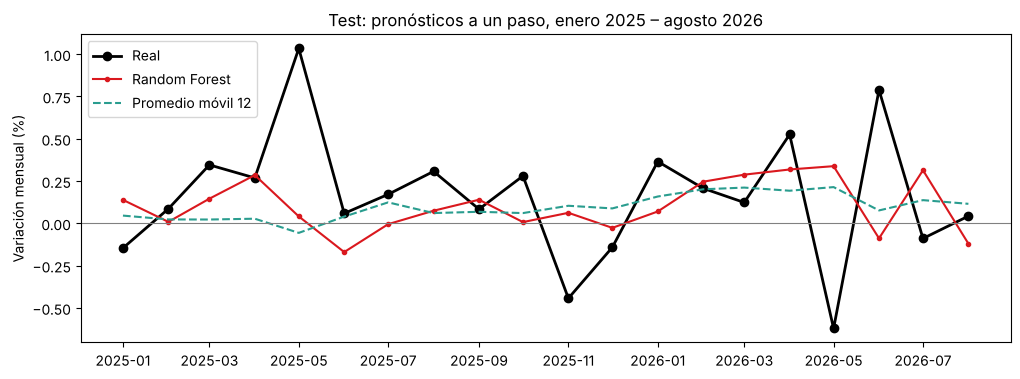

In [24]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y_test, color='black', marker='o', linewidth=2, label='Real')
ax.plot(pred_rf, color='#DA181E', marker='.', label='Random Forest')
ax.plot(X_test['media_12'], color='#2A9D8F', linestyle='--', label='Promedio móvil 12')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('Test: pronósticos a un paso, enero 2025 – agosto 2026')
ax.set_ylabel('Variación mensual (%)')
ax.legend()
plt.show()

El Random Forest sigue más de cerca los movimientos que el promedio móvil, pero también reacciona a señales que luego no se cumplen. El promedio móvil, al ser casi plano, se equivoca menos en promedio cuando la serie oscila sin dirección.

# 10. Pronóstico de uno y varios periodos: recursivo frente a directo (3.4)

## 10.1 El problema

El Random Forest aprendió a pronosticar **el próximo mes** usando `rezago_1`, `rezago_2`, etc. Si estamos en agosto de 2026 y queremos **octubre**, nos falta `rezago_1` (septiembre), que todavía no existe. Hay dos soluciones.

## 10.2 Estrategia recursiva

Se usa **el mismo modelo** varias veces, y cada pronóstico se usa como si fuera un dato real para el siguiente:

| Paso | Pronostica | `rezago_1` que usa |
|---:|---|---|
| 1 | septiembre | agosto (**real**) |
| 2 | octubre | septiembre (**pronosticado** en el paso 1) |
| 3 | noviembre | octubre (**pronosticado** en el paso 2) |

- **Ventaja:** un solo modelo para cualquier horizonte.
- **Desventaja:** los errores **se acumulan**: si el paso 1 se equivoca, el paso 2 parte de un dato equivocado.

## 10.3 Estrategia directa

Se entrena **un modelo distinto para cada horizonte**: uno aprende a pronosticar 1 mes adelante, otro 3 meses adelante, otro 12 meses adelante. Todos usan solo datos **reales** conocidos en el origen.

| Modelo | Aprende a pronosticar | Con qué datos |
|---|---|---|
| $h = 1$ | $y_{t+1}$ | $y_t, y_{t-1}, \dots$ |
| $h = 3$ | $y_{t+3}$ | $y_t, y_{t-1}, \dots$ |
| $h = 12$ | $y_{t+12}$ | $y_t, y_{t-1}, \dots$ |

- **Ventaja:** no acumula errores.
- **Desventaja:** hay que entrenar un modelo por horizonte, y cada uno tiene **menos filas** (con $h = 12$ se pierden 11 filas más), y la relación entre hoy y dentro de un año es más débil y más fácil de sobreajustar.

## 10.4 Implementación

**Qué vamos a hacer:** escribir dos funciones.

1. `variables_desde(historia, mes_objetivo)`: calcula los predictores **a partir de una historia** (los mismos de la parte 2), para el mes que se quiere pronosticar.
2. `tabla_directa(serie, h, hasta)`: construye la tabla de entrenamiento de un modelo directo de horizonte $h$, usando solo objetivos conocidos hasta `hasta`.

In [25]:
COLUMNAS = X.columns.tolist()
PARAMETROS = busqueda.best_params_

def variables_desde(historia, mes_objetivo):
    """Predictores calculados con la historia conocida, para pronosticar el mes `mes_objetivo` (1 a 12)."""
    fila = {f'rezago_{k}': historia.iloc[-k] for k in REZAGOS}
    fila['media_3'] = historia.iloc[-3:].mean()
    fila['media_12'] = historia.iloc[-12:].mean()
    fila['mes'] = mes_objetivo
    return pd.DataFrame([fila])[COLUMNAS]

def tabla_directa(serie, h, hasta):
    """Filas (predictores en el origen, objetivo h meses después), con objetivo hasta la fecha `hasta`."""
    filas, objetivos, fechas = [], [], []
    for i in range(12, len(serie) - h + 1):
        fecha_objetivo = serie.index[i - 1 + h]
        if fecha_objetivo > pd.Timestamp(hasta):
            break
        filas.append(variables_desde(serie.iloc[:i], fecha_objetivo.month).iloc[0])
        objetivos.append(serie.iloc[i - 1 + h])
        fechas.append(fecha_objetivo)
    return pd.DataFrame(filas, index=fechas), pd.Series(objetivos, index=fechas)

# Comprobación: con h = 1, la tabla directa debe coincidir con la tabla de la parte 2.
X_h1, y_h1 = tabla_directa(y, 1, '2024-12-01')
print('Filas con h = 1:', len(X_h1), '(la tabla de la parte 2 tiene', len(X_train), 'en Train)')
print('¿Coinciden los predictores?', np.allclose(X_h1.values, X_train.loc[X_h1.index].values))

Filas con h = 1: 228 (la tabla de la parte 2 tiene 228 en Train)
¿Coinciden los predictores? True


**Qué obtuvimos:** con $h = 1$ la tabla directa reproduce exactamente la tabla de la parte 2. Las funciones están bien.

Ahora las funciones que pronostican con cada estrategia, a partir de una historia.

In [26]:
def entrenar(Xe, ye):
    return RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, **PARAMETROS).fit(Xe, ye)

def pronostico_recursivo(modelo_h1, historia, pasos):
    """Usa el modelo de un paso repetidamente; cada pronóstico se agrega a la historia."""
    historia = historia.copy()
    resultado = []
    for _ in range(pasos):
        mes_siguiente = historia.index[-1] + pd.DateOffset(months=1)
        valor = modelo_h1.predict(variables_desde(historia, mes_siguiente.month))[0]
        historia.loc[mes_siguiente] = valor          # el pronóstico pasa a ser "historia"
        resultado.append(valor)
    return resultado

def pronostico_directo(modelos_por_h, historia):
    """Un modelo por horizonte; todos usan solo la historia real."""
    origen = historia.index[-1]
    return {h: m.predict(variables_desde(historia, (origen + pd.DateOffset(months=h)).month))[0]
            for h, m in modelos_por_h.items()}

## 10.5 Comparar las estrategias con origen móvil

**Qué vamos a hacer:** tomar 18 orígenes (junio y diciembre de cada año, de 2015 a 2023). En cada origen:

1. entrenar el modelo de un paso y los modelos directos de $h = 3, 6, 12$ **solo con datos hasta el origen**;
2. pronosticar 1, 3, 6 y 12 meses adelante con ambas estrategias;
3. comparar con la línea base (promedio de los 12 meses anteriores al origen, repetido para todos los horizontes).

Son 18 × 4 = 72 entrenamientos: tarda unos 20 segundos.

In [27]:
HORIZONTES = [1, 3, 6, 12]
origenes = pd.date_range('2015-06-01', '2023-12-01', freq='6MS')

registros = []
for origen in origenes:
    historia = y.loc[:origen]

    modelos = {h: entrenar(*tabla_directa(y, h, origen)) for h in HORIZONTES}
    recursivo = pronostico_recursivo(modelos[1], historia, pasos=12)
    directo = pronostico_directo(modelos, historia)
    base = historia.iloc[-12:].mean()

    for h in HORIZONTES:
        real = y.loc[origen + pd.DateOffset(months=h)]
        registros.append({'origen': origen, 'h': h,
                          'Recursivo': abs(real - recursivo[h - 1]),
                          'Directo': abs(real - directo[h]),
                          'Promedio móvil 12': abs(real - base)})

comparacion_h = pd.DataFrame(registros).groupby('h')[['Recursivo', 'Directo', 'Promedio móvil 12']].mean()
comparacion_h.round(3)

,Recursivo,Directo,Promedio móvil 12
h,,,
1,0.248,0.248,0.256
3,0.187,0.212,0.145
6,0.269,0.274,0.257
12,0.316,0.450,0.316


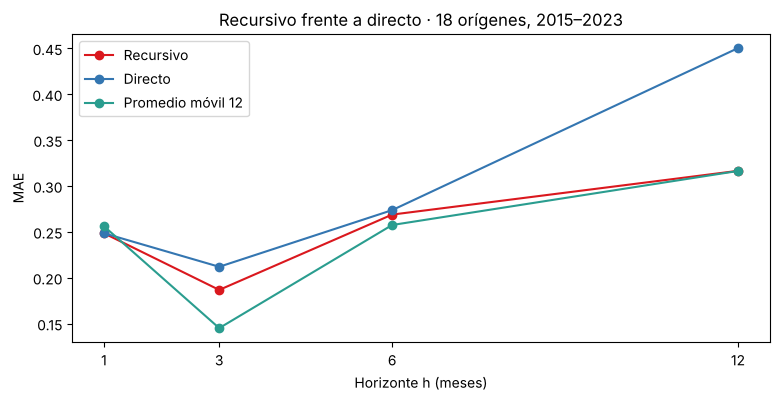

In [28]:
ax = comparacion_h.plot(marker='o', figsize=(9, 4), color=['#DA181E', '#3476B1', '#2A9D8F'])
ax.set_xlabel('Horizonte h (meses)')
ax.set_ylabel('MAE')
ax.set_xticks(HORIZONTES)
ax.set_title('Recursivo frente a directo · 18 orígenes, 2015–2023')
plt.show()

### Lectura

- **En $h = 1$ las dos estrategias son idénticas**: el modelo directo de un paso *es* el modelo recursivo.
- **La línea base iguala o supera a ambas estrategias** desde $h = 3$; solo en $h = 1$ el Random Forest es apenas mejor (≈ 0.25 frente a ≈ 0.26). Al pronosticar lejos, el modelo recursivo se apoya en sus propios pronósticos, que tienden al nivel promedio.
- **El directo empeora mucho en $h = 12$**: la relación entre la inflación de hoy y la de dentro de un año es débil, y con pocas filas el modelo aprende patrones de episodios concretos (por ejemplo, el alza de 2008) que no se repiten.
- Con solo 18 orígenes, las diferencias de centésimas en $h = 3$ y $h = 6$ no son concluyentes.

**Regla práctica:**

| Situación | Estrategia |
|---|---|
| horizontes cortos, serie con dinámica fuerte | recursiva |
| horizontes largos con muchos datos y una relación clara a ese horizonte | directa |
| series muy ruidosas como la inflación mensual | comparar ambas con una línea base; a menudo ninguna la supera |

# 11. Pronóstico de septiembre a noviembre de 2026

**Qué vamos a hacer:** entrenar con **todos** los datos hasta agosto de 2026 y pronosticar los próximos tres meses con ambas estrategias.

In [29]:
modelo_h1_total = entrenar(*tabla_directa(y, 1, y.index.max()))
modelos_total = {h: entrenar(*tabla_directa(y, h, y.index.max())) for h in [1, 2, 3]}

meses_futuros = pd.date_range(y.index.max() + pd.DateOffset(months=1), periods=3, freq='MS')

pd.DataFrame({
    'Recursivo': pronostico_recursivo(modelo_h1_total, y, pasos=3),
    'Directo': list(pronostico_directo(modelos_total, y).values()),
    'Promedio móvil 12': y.iloc[-12:].mean(),
}, index=meses_futuros).round(3)

,Recursivo,Directo,Promedio móvil 12
2026-09-01,0.076,0.076,0.094
2026-10-01,0.145,-0.027,0.094
2026-11-01,-0.079,0.021,0.094


**Cómo leer la tabla:** ambas estrategias dan el mismo valor para septiembre (es el mismo modelo) y difieren en octubre y noviembre. Las diferencias con el promedio móvil son de décimas, **mucho menores que la incertidumbre** que vimos en los intervalos del Día 3 (± 0.65 puntos). Random Forest no ofrece intervalos directamente; si se necesitan, se pueden aproximar con los errores del backtesting (Día 6).

# 12. Reto de cierre: exportaciones

Las exportaciones son una serie con **más estructura** que la inflación (crecimiento, estacionalidad, efecto del petróleo). Repite el procedimiento con `exportaciones_fob_musd` desde 2005:

1. Trabaja con la **variación mensual en porcentaje** (`pct_change() * 100`) para que la serie sea estacionaria (Día 2) y Random Forest no tenga que extrapolar.
2. Construye la tabla de variables con `tabla_variables`. Agrega una columna con la **variación del precio del petróleo WTI del mes anterior** (`series['precio_wti_usd'].pct_change().shift(1) * 100`). ¿Por qué lleva `shift(1)`?
3. Separa Train (hasta 2024) y Test, valida con `TimeSeriesSplit` y ajusta con `GridSearchCV`.
4. Compara con el promedio móvil de 12 en validación y en Test. ¿Ahora Random Forest gana?
5. Revisa la importancia de variables. ¿Qué lugar ocupa el petróleo?

In [30]:
exportaciones = series['exportaciones_fob_musd'].loc['2005':].dropna()
variacion_exportaciones = (exportaciones.pct_change() * 100).dropna()

print(f'{len(variacion_exportaciones)} meses de variación mensual de exportaciones')
variacion_exportaciones.describe().round(2)

259 meses de variación mensual de exportaciones


count    259.00
mean       1.10
std        9.81
min      -32.68
25%       -4.94
50%        0.57
75%        7.49
max       39.01
Name: exportaciones_fob_musd, dtype: float64

In [31]:
# A partir de aquí escribe tus propias celdas.

## Checklist del día

- [ ] ¿Cada predictor de mi tabla se conoce **antes** del mes que pronostico (`shift` antes de `rolling`)?
- [ ] ¿Revisé que ninguna variable tenga correlación sospechosamente cercana a 1 con el objetivo?
- [ ] ¿Separé Train y Test por fecha y validé con `TimeSeriesSplit`, nunca con un K-Fold mezclado?
- [ ] ¿Comparé contra la línea base **en los mismos pliegues**?
- [ ] ¿Entendí qué hace cada hiperparámetro antes de usar `GridSearchCV`?
- [ ] ¿Interpreté la importancia de variables como predictiva y no causal?
- [ ] ¿Sé si mi pronóstico a varios meses es recursivo o directo, y por qué?

**Puente hacia el Día 5:** Random Forest no superó claramente a la línea base usando solo el pasado de la inflación. Mañana le daremos más información: combinaremos ARIMA con Random Forest en un **modelo híbrido** y estudiaremos qué indicadores macroeconómicos y qué cambios estructurales ayudan a entender los pronósticos.